# Аналитика моделей Hugging Face Hub

Лабораторная работа №1: сбор данных с веб-ресурса (официальный REST API
`huggingface.co/api/models`), хранение в **SQLite** с инкрементальной
подгрузкой и **5 разноплановых агрегирующих запросов** на `pandas` +
`SQLAlchemy`.

Данные нормализованы по схеме 1:M: `authors` ← `models` → `licenses`
(у лицензии хранится готовая `category`). Все запросы ниже строятся либо
выражениями SQLAlchemy (`select`/`func`), либо читаются в `pandas` через
`pd.read_sql` и доагрегируются уже в DataFrame.

**Содержание:**
1. Концентрация рынка вендоров (CR10, HHI)
2. Лицензионный ландшафт
3. Динамика специализаций по месяцам
4. Виральность против внедрения (likes / downloads)
5. Влияние лицензии на адопшн (медиана/среднее загрузок)


In [1]:
import os, sys

# делаем проект (родительскую папку notebook-а) импортируемым
for _p in (os.getcwd(), os.path.abspath(os.path.join(os.getcwd(), os.pardir))):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import select, func
from IPython.display import display

from models import engine, Model, Author, License

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

overview = pd.read_sql(
    select(
        func.count(Model.id).label("models"),
        func.count(func.distinct(Model.author_id)).label("authors"),
        func.count(func.distinct(Model.license_id)).label("licenses"),
        func.min(Model.created_at).label("first_created"),
        func.max(Model.created_at).label("last_created"),
    ),
    engine,
)
print("Датасет в БД:")
overview


Датасет в БД:


,models,authors,licenses,first_created,last_created
0,4035,1032,38,2022-03-02 23:29:04,2026-10-14 19:35:17


## 1. Концентрация рынка вендоров

Считаем суммарные загрузки по каждому автору и измеряем, какую долю рынка
контролирует топ-10 организаций. Метрики: **CR10** (доля топ-10) и **HHI**
(индекс Херфиндаля–Хиршмана; <1500 — низкая концентрация, >2500 — высокая).

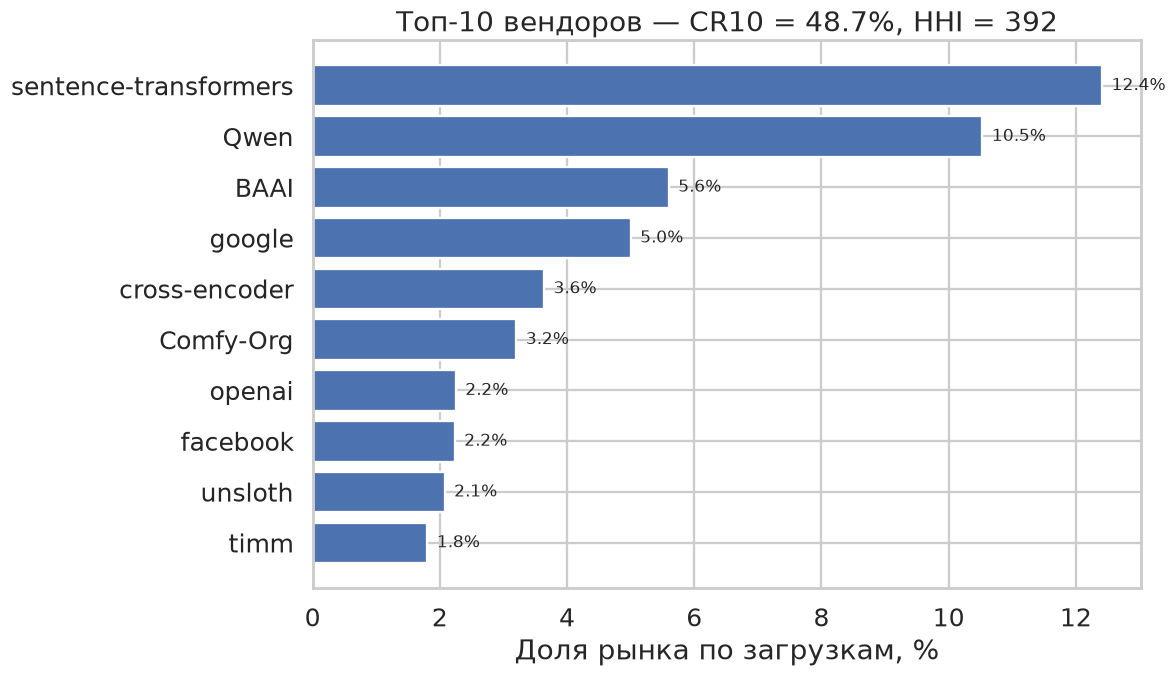

Суммарно загрузок: 2,514,180,641 у 1032 авторов


,author,models,downloads,share_%,cum_%
0,sentence-transformers,38,312028448,12.410741,12.410741
1,Qwen,199,264711263,10.528729,22.939470
2,BAAI,16,140736267,5.597699,28.537169
3,google,108,125708644,4.999985,33.537154
4,cross-encoder,16,91429222,3.636541,37.173695
5,Comfy-Org,58,80493783,3.201591,40.375286
6,openai,17,56558813,2.249592,42.624878
7,facebook,95,56139978,2.232933,44.857812
8,unsloth,157,52151545,2.074296,46.932108
9,timm,104,45318977,1.802535,48.734642


In [2]:
downloads_by_author = pd.read_sql(
    select(
        Author.name.label("author"),
        func.count(Model.id).label("models"),
        func.sum(Model.downloads).label("downloads"),
    )
    .join(Author, Model.author_id == Author.id)
    .group_by(Author.name)
    .order_by(func.sum(Model.downloads).desc()),
    engine,
)

total_downloads = downloads_by_author["downloads"].sum()
top10 = downloads_by_author.head(10).copy()
top10["share_%"] = top10["downloads"] / total_downloads * 100
top10["cum_%"] = top10["share_%"].cumsum()

cr10 = top10["share_%"].sum()
shares = downloads_by_author["downloads"] / total_downloads
hhi = float((shares ** 2).sum()) * 10000

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(top10["author"][::-1], top10["share_%"][::-1], color="#4c72b0")
for i, v in enumerate(top10["share_%"][::-1]):
    ax.text(v + 0.15, i, f"{v:.1f}%", va="center", fontsize=11)
ax.set_xlabel("Доля рынка по загрузкам, %")
ax.set_title(f"Топ-10 вендоров — CR10 = {cr10:.1f}%, HHI = {hhi:.0f}")
fig.tight_layout()
plt.show()

print(f"Суммарно загрузок: {total_downloads:,.0f} у {len(downloads_by_author)} авторов")
top10


## 2. Лицензионный ландшафт

Соотношение категорий лицензий: полностью открытые (`open`: Apache-2.0, MIT,
BSD, CC-BY), копилефт (`copyleft`: GPL/AGPL/MPL), открытые веса с
ограничениями (`restricted`: Llama, Gemma, RAIL, DeepSeek), некоммерческие
(`noncommercial`: CC-BY-NC), прочее и модели без указанной лицензии
(`unknown`).

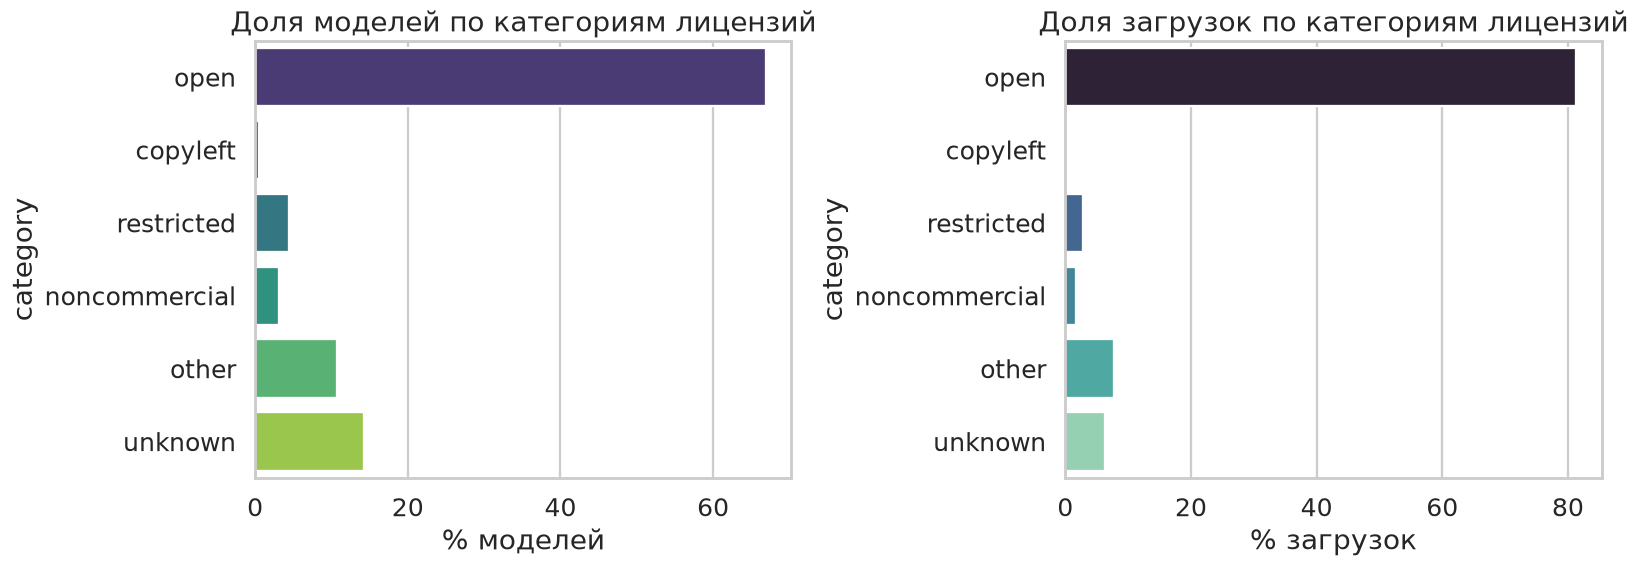

,category,models,downloads,models_%,downloads_%
0,open,2700,2043771837,66.914498,81.289777
1,unknown,577,156833774,14.299876,6.237968
2,other,435,196040404,10.780669,7.797387
3,restricted,180,70618447,4.460967,2.808806
4,noncommercial,125,41925571,3.097893,1.667564
5,copyleft,18,4990608,0.446097,0.198498


In [3]:
cat_expr = func.coalesce(License.category, "unknown").label("category")
landscape = pd.read_sql(
    select(
        cat_expr,
        func.count(Model.id).label("models"),
        func.sum(Model.downloads).label("downloads"),
    )
    .outerjoin(License, Model.license_id == License.id)
    .group_by(cat_expr)
    .order_by(func.count(Model.id).desc()),
    engine,
)
landscape["models_%"] = landscape["models"] / landscape["models"].sum() * 100
landscape["downloads_%"] = landscape["downloads"] / landscape["downloads"].sum() * 100

order = [c for c in ["open", "copyleft", "restricted", "noncommercial", "other", "unknown"]
         if c in set(landscape["category"])]
plot_df = landscape.set_index("category").loc[order].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(data=plot_df, x="models_%", y="category", hue="category",
            legend=False, palette="viridis", ax=axes[0])
axes[0].set(xlabel="% моделей", title="Доля моделей по категориям лицензий")
sns.barplot(data=plot_df, x="downloads_%", y="category", hue="category",
            legend=False, palette="mako", ax=axes[1])
axes[1].set(xlabel="% загрузок", title="Доля загрузок по категориям лицензий")
fig.tight_layout()
plt.show()

landscape


## 3. Динамика специализаций

Группируем модели по месяцу создания и `pipeline_tag`, чтобы увидеть смещение
интереса сообщества (например, рост мультимодальных `image-text-to-text`
относительно классических задач).

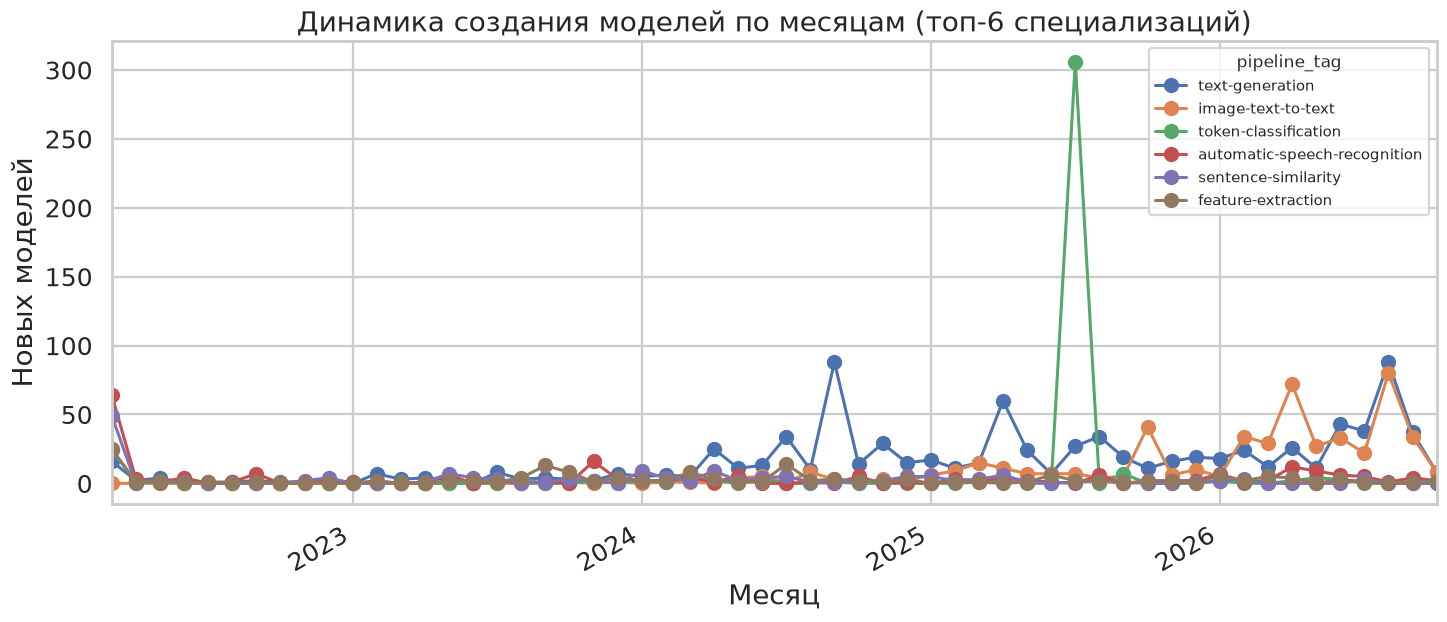

pipeline_tag,text-generation,image-text-to-text,token-classification,automatic-speech-recognition,sentence-similarity,feature-extraction
month,,,,,,
2025-11-01,16,6,0,2,0,2
2025-12-01,19,10,0,2,1,0
2026-01-01,18,5,2,7,2,6
2026-02-01,24,34,0,1,3,2
2026-03-01,12,29,0,2,0,5
2026-04-01,26,72,2,12,0,4
2026-05-01,11,27,4,9,0,0
2026-06-01,43,33,3,6,0,3
2026-07-01,38,22,0,5,3,1


In [4]:
created = pd.read_sql(select(Model.created_at, Model.pipeline_tag), engine)
created["created_at"] = pd.to_datetime(created["created_at"])
created["month"] = created["created_at"].dt.to_period("M").dt.to_timestamp()

top_tags = created["pipeline_tag"].dropna().value_counts().head(6).index.tolist()
monthly = (
    created[created["pipeline_tag"].isin(top_tags)]
    .pivot_table(index="month", columns="pipeline_tag",
                 values="created_at", aggfunc="count")
    .fillna(0).astype(int)[top_tags]
)

fig, ax = plt.subplots(figsize=(13.5, 6))
monthly.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Динамика создания моделей по месяцам (топ-6 специализаций)")
ax.set(xlabel="Месяц", ylabel="Новых моделей")
ax.legend(title="pipeline_tag", fontsize=10, title_fontsize=11)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

monthly.tail(12)


## 4. Виральность против внедрения

Коэффициент `likes / downloads` по авторам отделяет «исследовательские
любимчики» (много лайков на загрузку) от «рабочих утилит» (огромные загрузки
при скромном числе лайков). Чтобы убрать шум, оставляем авторов с реальным
адопшном (суммарные загрузки ≥ порога и ≥ 2 моделей).

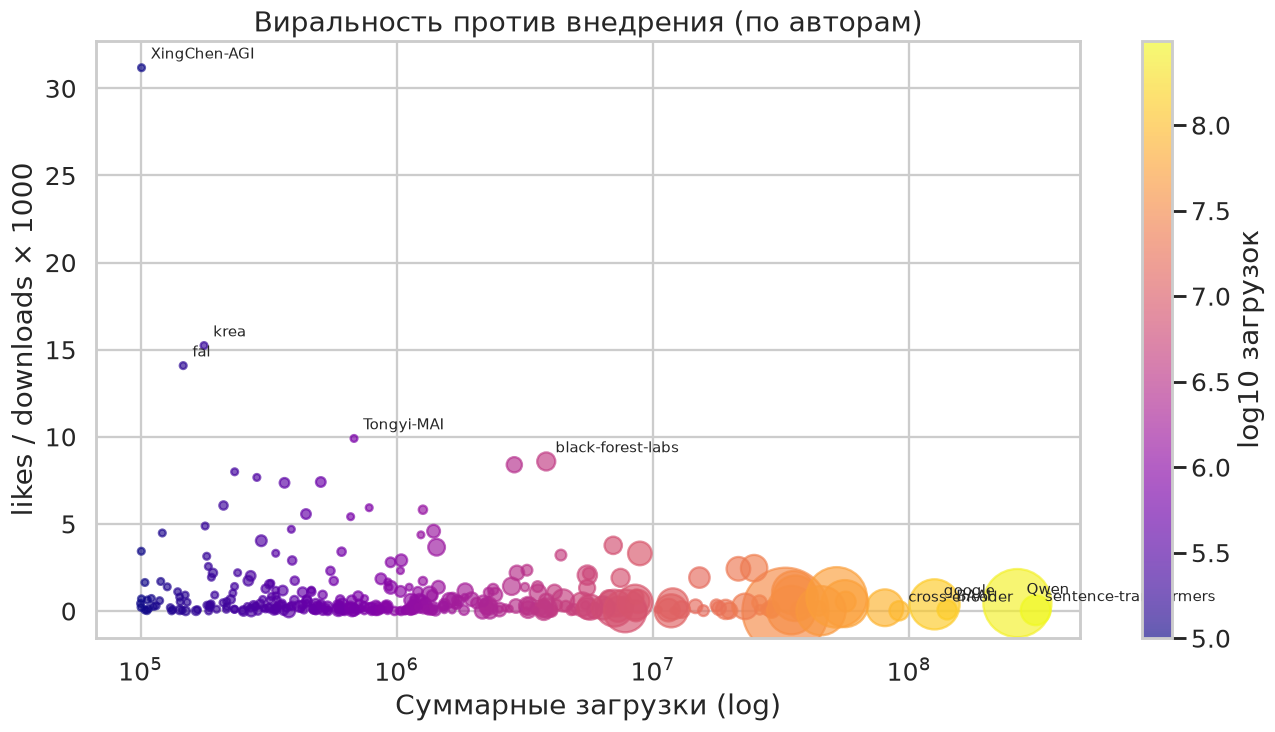

Авторов в выборке (downloads >= 50,000 и >= 2 моделей): 362

Самые 'виральные' (лайков на 1000 загрузок):


,author,models,downloads,likes,engagement
344,XingChen-AGI,2,100861,3145,31.181527
682,krea,2,176899,2695,15.234682
558,fal,2,146700,2066,14.083163
319,Tongyi-MAI,2,681176,6745,9.901993
431,black-forest-labs,14,3833155,32895,8.581704


Самые 'внедряемые' (максимум загрузок):


,author,models,downloads,likes,engagement
903,sentence-transformers,38,312028448,12155,0.038955
253,Qwen,199,264711263,119810,0.452606
38,BAAI,16,140736267,9211,0.065449
585,google,108,125708644,47820,0.380403
491,cross-encoder,16,91429222,903,0.009876


In [5]:
author_stats = pd.read_sql(
    select(
        Author.name.label("author"),
        func.count(Model.id).label("models"),
        func.sum(Model.downloads).label("downloads"),
        func.sum(Model.likes).label("likes"),
    )
    .join(Author, Model.author_id == Author.id)
    .group_by(Author.name),
    engine,
)

MIN_DOWNLOADS = 50_000
active = author_stats[(author_stats["downloads"] >= MIN_DOWNLOADS)
                      & (author_stats["models"] >= 2)].copy()
active["engagement"] = active["likes"] / active["downloads"] * 1000  # лайков на 1000 загрузок

fig, ax = plt.subplots(figsize=(12.5, 7))
sc = ax.scatter(active["downloads"], active["engagement"],
                s=active["models"] * 10, alpha=0.65,
                c=np.log10(active["downloads"]), cmap="plasma")
ax.set_xscale("log")
ax.set(xlabel="Суммарные загрузки (log)", ylabel="likes / downloads × 1000")
ax.set_title("Виральность против внедрения (по авторам)")
fig.colorbar(sc, ax=ax, label="log10 загрузок")

top_viral = active.nlargest(5, "engagement")
top_used = active.nlargest(5, "downloads")
for _, r in pd.concat([top_viral, top_used]).iterrows():
    ax.annotate(r["author"], (r["downloads"], r["engagement"]),
                fontsize=10, xytext=(6, 6), textcoords="offset points")
fig.tight_layout()
plt.show()

print(f"Авторов в выборке (downloads >= {MIN_DOWNLOADS:,} и >= 2 моделей): {len(active)}")
print("\nСамые 'виральные' (лайков на 1000 загрузок):")
display(top_viral[["author", "models", "downloads", "likes", "engagement"]])
print("Самые 'внедряемые' (максимум загрузок):")
display(top_used[["author", "models", "downloads", "likes", "engagement"]])


## 5. Влияние лицензии на адопшн

Сравниваем среднее и медианное число загрузок моделей по категориям лицензий:
насколько полностью открытые лицензии (`open`) обгоняют открытые веса с
ограничениями (`restricted`) и некоммерческие.

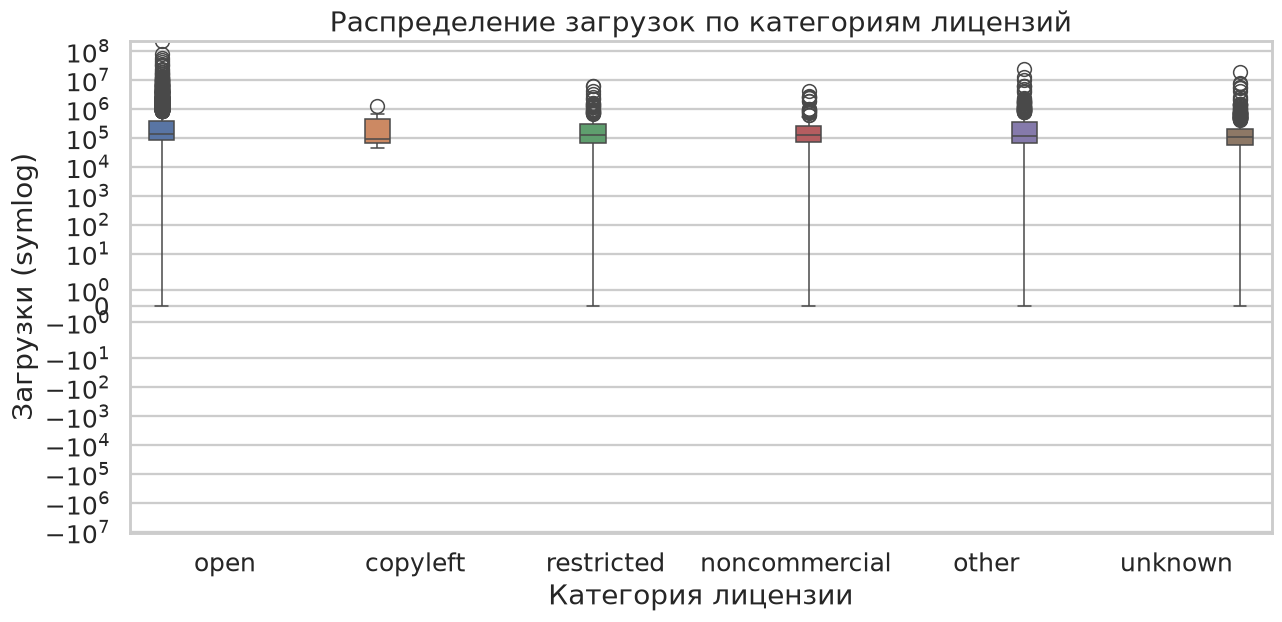

,models,mean_downloads,median_downloads
category,,,
open,2700,756952.532222,137784.5
noncommercial,125,335404.568000,127577.0
restricted,180,392324.705556,125077.0
other,435,450667.595402,118310.0
unknown,577,271808.967071,103752.0
copyleft,18,277256.000000,94296.5


In [6]:
rows = pd.read_sql(
    select(
        func.coalesce(License.category, "unknown").label("category"),
        Model.downloads,
    ).outerjoin(License, Model.license_id == License.id),
    engine,
)
summary = (
    rows.groupby("category")["downloads"]
    .agg(["count", "mean", "median"])
    .sort_values("median", ascending=False)
)
summary.columns = ["models", "mean_downloads", "median_downloads"]

plot_order = [c for c in ["open", "copyleft", "restricted", "noncommercial", "other", "unknown"]
              if c in summary.index]
rows["category"] = pd.Categorical(rows["category"], categories=plot_order, ordered=True)

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=rows, x="category", y="downloads", hue="category",
            legend=False, ax=ax)
ax.set_yscale("symlog")
ax.set(xlabel="Категория лицензии", ylabel="Загрузки (symlog)",
       title="Распределение загрузок по категориям лицензий")
fig.tight_layout()
plt.show()

summary


## Выводы

По собранному датасету (**4,035 моделей**, 1,032 авторов,
период 2022-03-02 → 2026-10-14):

1. **Концентрация рынка.** Топ-10 вендоров (sentence-transformers, Qwen, BAAI, …) удерживают
   **48.7%** всех загрузок (CR10), лидер — около 12%.
   При этом индекс Херфиндаля–Хиршмана **HHI ≈ 392** — ниже порога
   концентрации (1500): единого монополиста нет, основная масса авторов
   формирует «длинный хвост».
2. **Лицензии.** Полностью открытые лицензии (`open`: Apache-2.0, MIT, BSD,
   CC-BY) — **66.9%** моделей; открытые веса с ограничениями
   (`restricted`: Llama, Gemma, RAIL) — **4.5%**,
   некоммерческие — **3.1%**. Ещё **577** моделей
   вообще не указали лицензию, что снижает их юридическую пригодность для
   продакшена.
3. **Специализации.** Самая массовая задача — `text-generation`, а наибольший
   прирост числа новых моделей за последние месяцы показывает
   `image-text-to-text` — подтверждается сдвиг интереса к мультимодальным
   и новым нишам.
4. **Виральность vs внедрение.** «Любимчик сообщества» (максимум лайков на
   загрузку) — **XingChen-AGI**, а лидер по реальному адопшну —
   **sentence-transformers**. Метрика `likes/downloads` хорошо разделяет
   исследовательские релизы и рабочие утилиты (в выборке 362
   значимых авторов).
5. **Лицензия → адопшн.** Открытые лицензии впереди по адопшну: среднее число
   загрузок `open`-моделей — **756,953**, примерно в
   **1.9×** выше, чем у `restricted`
   (**392,325**) — за счёт флагманских хитов. По **медиане**
   разрыв меньше: **137,784** против **125,077**
   (≈1.1×), т.е. типичная модель с ограниченной лицензией
   (Llama, Gemma) используется почти так же, как типичная открытая: открытость
   даёт преимущество, но не является единственным фактором успеха.

*Технически все пять запросов используют разные типы агрегации: оконные доли и
HHI, категориальные сводки с `COALESCE`+`LEFT JOIN`, временны́е ряды
(pivot по месяцам), отношения метрик с фильтрацией и сравнение распределений
(медиана/среднее + boxplot).*
